In [ ]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split, cross_val_score
from sklearn.preprocessing import LabelEncoder, StandardScaler
from sklearn.tree import DecisionTreeClassifier, plot_tree
from sklearn.svm import SVC
from sklearn.metrics import (
    accuracy_score, precision_score, recall_score, f1_score,
    roc_auc_score, roc_curve, confusion_matrix, classification_report
)

sns.set_theme(style="whitegrid", palette="muted")
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 10
plt.rcParams["axes.titlesize"] = 12
plt.rcParams["axes.titleweight"] = "bold"

print("Libraries successfully loaded and visual configuration set.")


Libraries successfully loaded and visual configuration set.


In [ ]:
df = pd.read_csv("student-mat.csv", sep=";")

df["Final_Status"] = np.where(df["G3"] >= 10, "Pass", "Fail")
df["Target"] = np.where(df["G3"] >= 10, 1, 0)

print(f"Dataset Shape: {df.shape}")
print("\nTarget Class Distribution:")
print(df["Final_Status"].value_counts())
print(f"Overall Pass Rate: {df['Target'].mean()*100:.2f}%")

print("\nFirst 5 Records Preview:")
display(df.head())


Mathematics Dataset Shape: (395, 35)

Target Class Distribution:
Final_Status
Pass    265
Fail    130
Name: count, dtype: int64
Overall Pass Rate: 67.09%

First 5 Records Preview:


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2,G3,Final_Status,Target
0,GP,F,18,U,GT3,A,4,4,at_home,teacher,course,mother,2,2,0,yes,no,no,no,yes,yes,no,no,4,3,4,1,1,3,6,5,6,6,Fail,0
1,GP,F,17,U,GT3,T,1,1,at_home,other,course,father,1,2,0,no,yes,no,no,no,yes,yes,no,5,3,3,1,1,3,4,5,5,6,Fail,0
2,GP,F,15,U,LE3,T,1,1,at_home,other,other,mother,1,2,3,yes,no,yes,no,yes,yes,yes,no,4,3,2,2,3,3,10,7,8,10,Pass,1
3,GP,F,15,U,GT3,T,4,2,health,services,home,mother,1,3,0,no,yes,yes,yes,yes,yes,yes,yes,3,2,2,1,1,5,2,15,14,15,Pass,1
4,GP,F,16,U,GT3,T,3,3,other,other,home,father,1,2,0,no,yes,yes,no,yes,yes,no,no,4,3,2,1,2,5,4,6,10,10,Pass,1


In [ ]:
print("Total Missing Values in Dataset:", df.isnull().sum().sum())

features_to_drop = ["G3", "Final_Status", "Target"]
X_raw = df.drop(columns=features_to_drop)
y = df["Target"]

categorical_cols = X_raw.select_dtypes(include=["object"]).columns
X_encoded = X_raw.copy()

label_encoders = {}
for col in categorical_cols:
    le = LabelEncoder()
    X_encoded[col] = le.fit_transform(X_raw[col].astype(str))
    label_encoders[col] = le

print(f"Feature Matrix Shape: {X_encoded.shape} (30 Predictor Variables)")
print(f"Categorical Variables Encoded: {list(categorical_cols)}")
print("\nEncoded Feature Matrix Preview (First 5 Rows):")
display(X_encoded.head())


Total Missing Values in Dataset: 0
Feature Matrix Shape: (395, 32) (30 Predictor Variables)
Categorical Variables Encoded: ['school', 'sex', 'address', 'famsize', 'Pstatus', 'Mjob', 'Fjob', 'reason', 'guardian', 'schoolsup', 'famsup', 'paid', 'activities', 'nursery', 'higher', 'internet', 'romantic']

Encoded Feature Matrix Preview (First 5 Rows):


,school,sex,age,address,famsize,Pstatus,Medu,Fedu,Mjob,Fjob,reason,guardian,traveltime,studytime,failures,schoolsup,famsup,paid,activities,nursery,higher,internet,romantic,famrel,freetime,goout,Dalc,Walc,health,absences,G1,G2
0,0,0,18,1,0,0,4,4,0,4,0,1,2,2,0,1,0,0,0,1,1,0,0,4,3,4,1,1,3,6,5,6
1,0,0,17,1,0,1,1,1,0,2,0,0,1,2,0,0,1,0,0,0,1,1,0,5,3,3,1,1,3,4,5,5
2,0,0,15,1,1,1,1,1,0,2,2,1,1,2,3,1,0,1,0,1,1,1,0,4,3,2,2,3,3,10,7,8
3,0,0,15,1,0,1,4,2,1,3,1,1,1,3,0,0,1,1,1,1,1,1,1,3,2,2,1,1,5,2,15,14
4,0,0,16,1,0,1,3,3,2,2,1,0,1,2,0,0,1,1,0,1,1,0,0,4,3,2,1,2,5,4,6,10


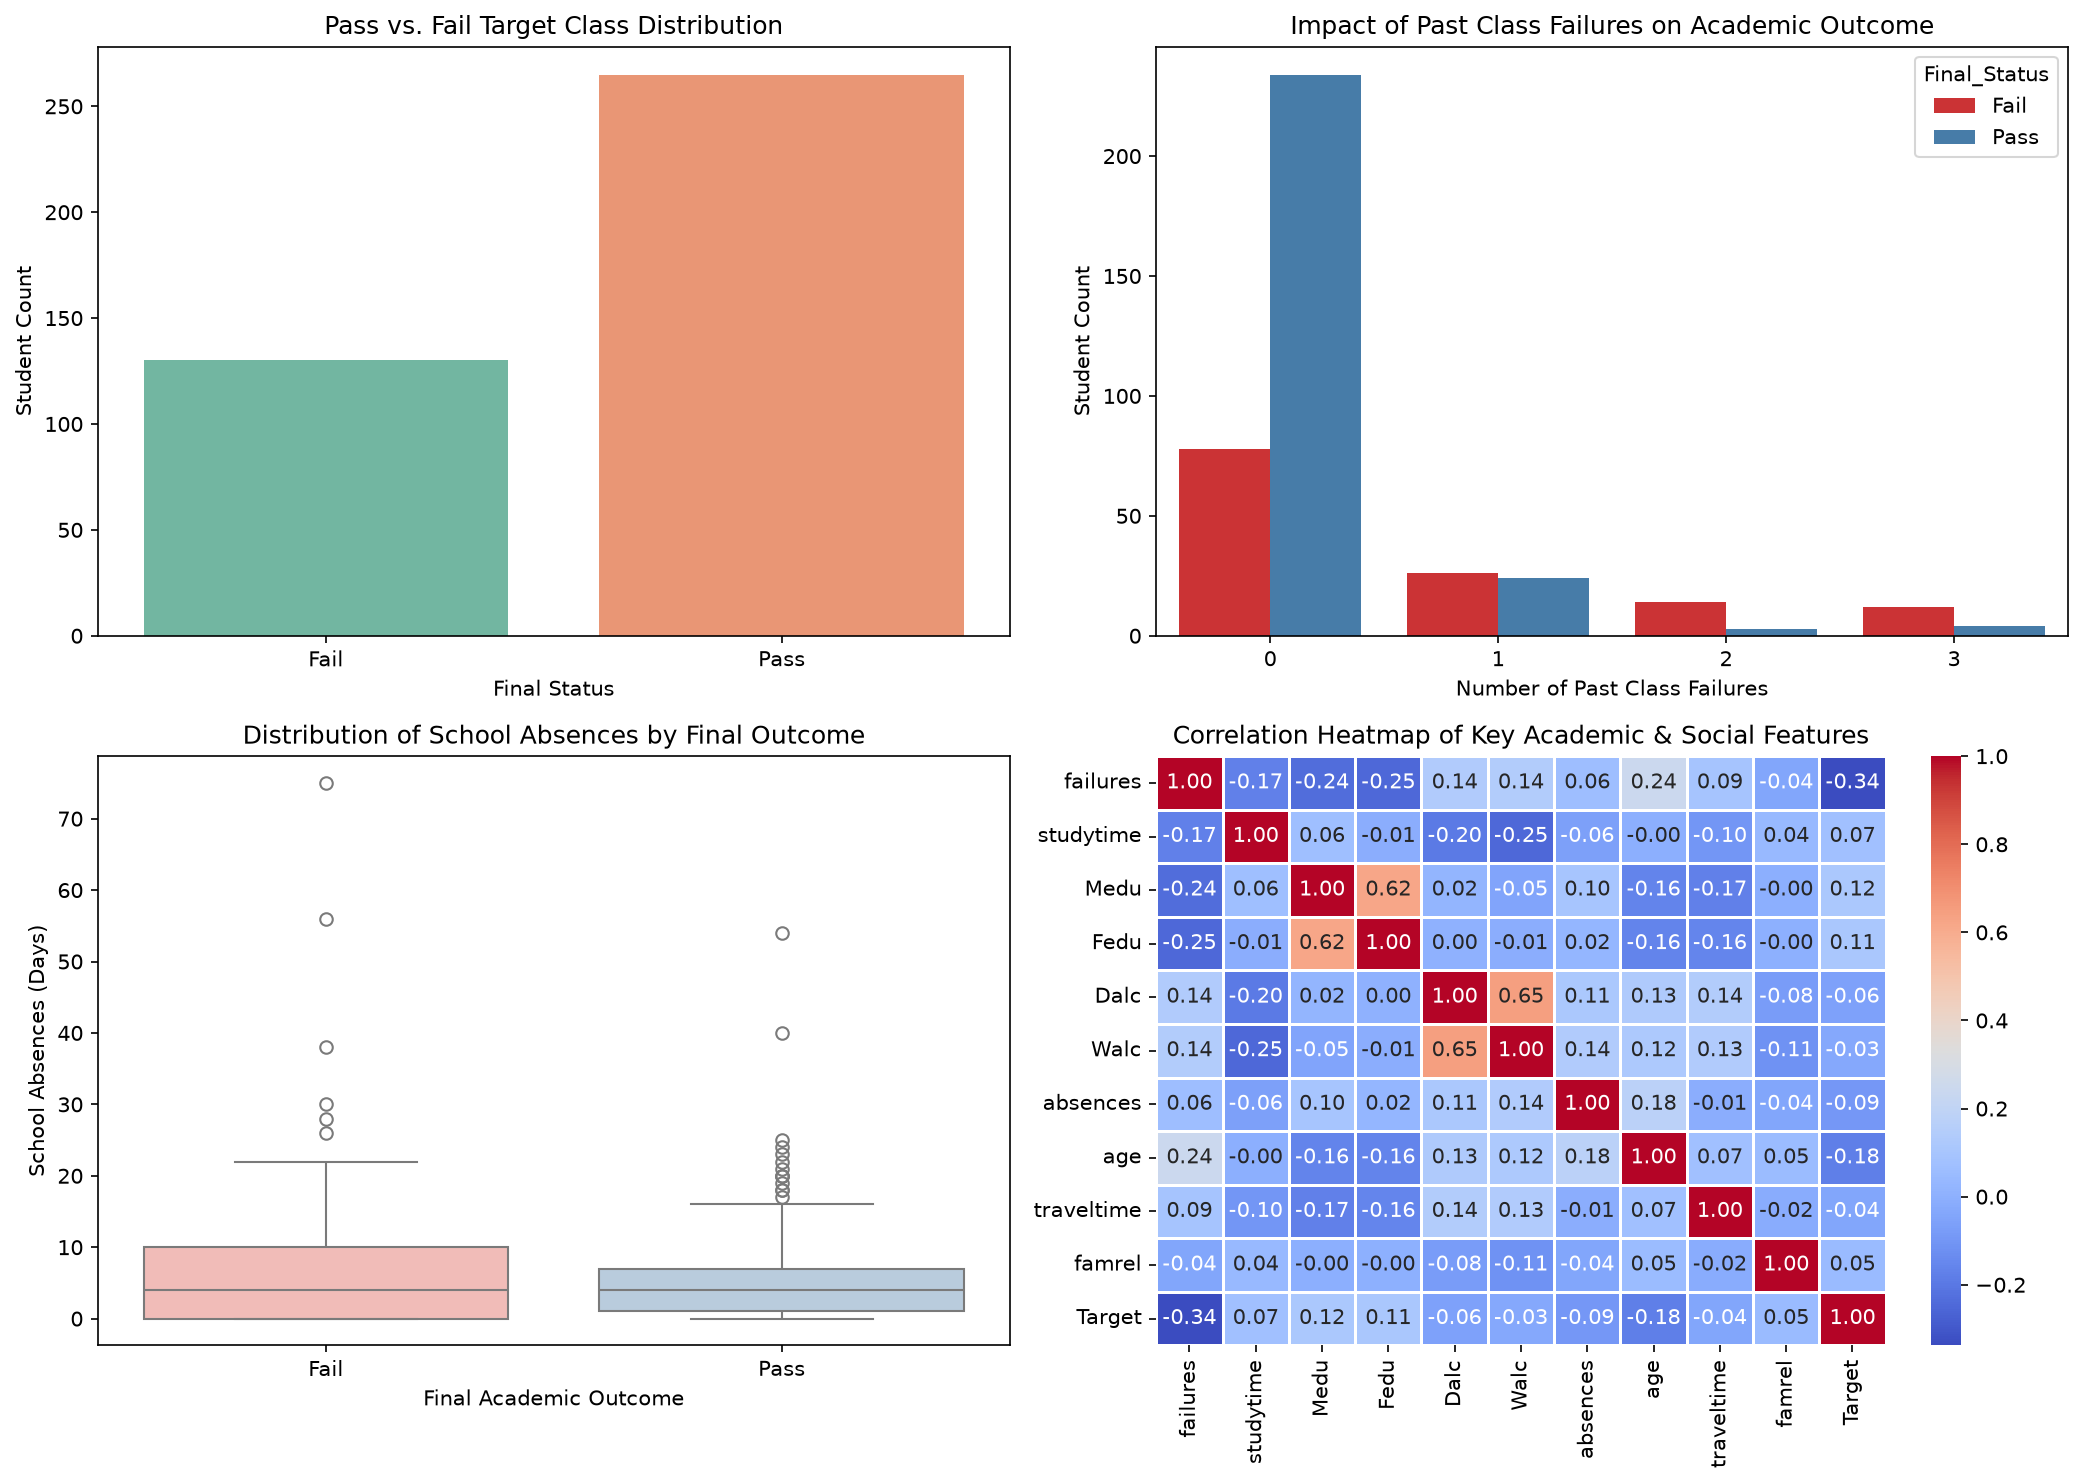

In [ ]:
fig, axes = plt.subplots(2, 2, figsize=(14, 10))

sns.countplot(
    x="Final_Status", data=df, ax=axes[0, 0], palette="Set2", hue="Final_Status"
)
axes[0, 0].set_title("Pass vs. Fail Target Class Distribution")
axes[0, 0].set_xlabel("Final Status")
axes[0, 0].set_ylabel("Student Count")

sns.countplot(
    x="failures", hue="Final_Status", data=df, ax=axes[0, 1], palette="Set1"
)
axes[0, 1].set_title("Impact of Past Class Failures on Academic Outcome")
axes[0, 1].set_xlabel("Number of Past Class Failures")
axes[0, 1].set_ylabel("Student Count")

sns.boxplot(
    x="Final_Status", y="absences", data=df, ax=axes[1, 0], palette="Pastel1", hue="Final_Status"
)
axes[1, 0].set_title("Distribution of School Absences by Final Outcome")
axes[1, 0].set_xlabel("Final Academic Outcome")
axes[1, 0].set_ylabel("School Absences (Days)")

corr_cols = [
    "failures", "studytime", "Medu", "Fedu", "Dalc", "Walc", 
    "absences", "age", "traveltime", "famrel", "Target"
]
sns.heatmap(
    df[corr_cols].corr(),
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    ax=axes[1, 1],
    cbar=True,
    linewidths=0.5
)
axes[1, 1].set_title("Correlation Heatmap of Key Academic & Social Features")

plt.tight_layout()
plt.show()


In [ ]:
X_train, X_test, y_train, y_test = train_test_split(
    X_encoded, y, test_size=0.20, random_state=42, stratify=y
)

scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train)
X_test_scaled = scaler.transform(X_test)

dt_model = DecisionTreeClassifier(max_depth=4, criterion="gini", min_samples_split=10, random_state=42)
dt_model.fit(X_train, y_train)
y_pred_dt = dt_model.predict(X_test)
y_prob_dt = dt_model.predict_proba(X_test)[:, 1]

svm_model = SVC(kernel="rbf", C=1.0, gamma="scale", probability=True, random_state=42)
svm_model.fit(X_train_scaled, y_train)
y_pred_svm = svm_model.predict(X_test_scaled)
y_prob_svm = svm_model.predict_proba(X_test_scaled)[:, 1]

print(f"Dataset split completed: Training set ({X_train.shape[0]} samples), Test set ({X_test.shape[0]} samples).")
print("Decision Tree Classifier trained (max_depth=4, criterion='gini').")
print("Support Vector Classifier (SVM) trained (kernel='rbf', C=1.0, StandardScaler applied).")


Dataset split completed: Training set (316 samples), Test set (79 samples).
Decision Tree Classifier trained (max_depth=4, criterion='gini').
Support Vector Classifier (SVM) trained (kernel='rbf', C=1.0, StandardScaler applied).


In [ ]:
def evaluate_model(y_true, y_pred, y_prob, model, X_train_data, y_train_data):
    cv_scores = cross_val_score(model, X_train_data, y_train_data, cv=5, scoring='accuracy')
    return {
        "Accuracy": accuracy_score(y_true, y_pred),
        "Precision (Pass)": precision_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (Pass)": recall_score(y_true, y_pred, pos_label=1, zero_division=0),
        "Recall (Fail - Risk)": recall_score(y_true, y_pred, pos_label=0, zero_division=0),
        "F1-Score": f1_score(y_true, y_pred, zero_division=0),
        "ROC-AUC": roc_auc_score(y_true, y_prob),
        "5-Fold CV Accuracy": cv_scores.mean()
    }

metrics_dt = evaluate_model(y_test, y_pred_dt, y_prob_dt, dt_model, X_train, y_train)
metrics_svm = evaluate_model(y_test, y_pred_svm, y_prob_svm, svm_model, X_train_scaled, y_train)

comparison_df = pd.DataFrame([metrics_dt, metrics_svm], index=["Decision Tree", "SVM Classifier (RBF)"])
print("--- Machine Learning Model Performance Metrics Comparison ---")
display(comparison_df.round(4))


--- Machine Learning Model Performance Metrics Comparison ---


,Accuracy,Precision (Pass),Recall (Pass),Recall (Fail - Risk),F1-Score,ROC-AUC,5-Fold CV Accuracy
Decision Tree,0.8734,0.9388,0.8679,0.8846,0.9020,0.9267,0.8955
SVM Classifier (RBF),0.7975,0.8491,0.8491,0.6923,0.8491,0.8919,0.8417


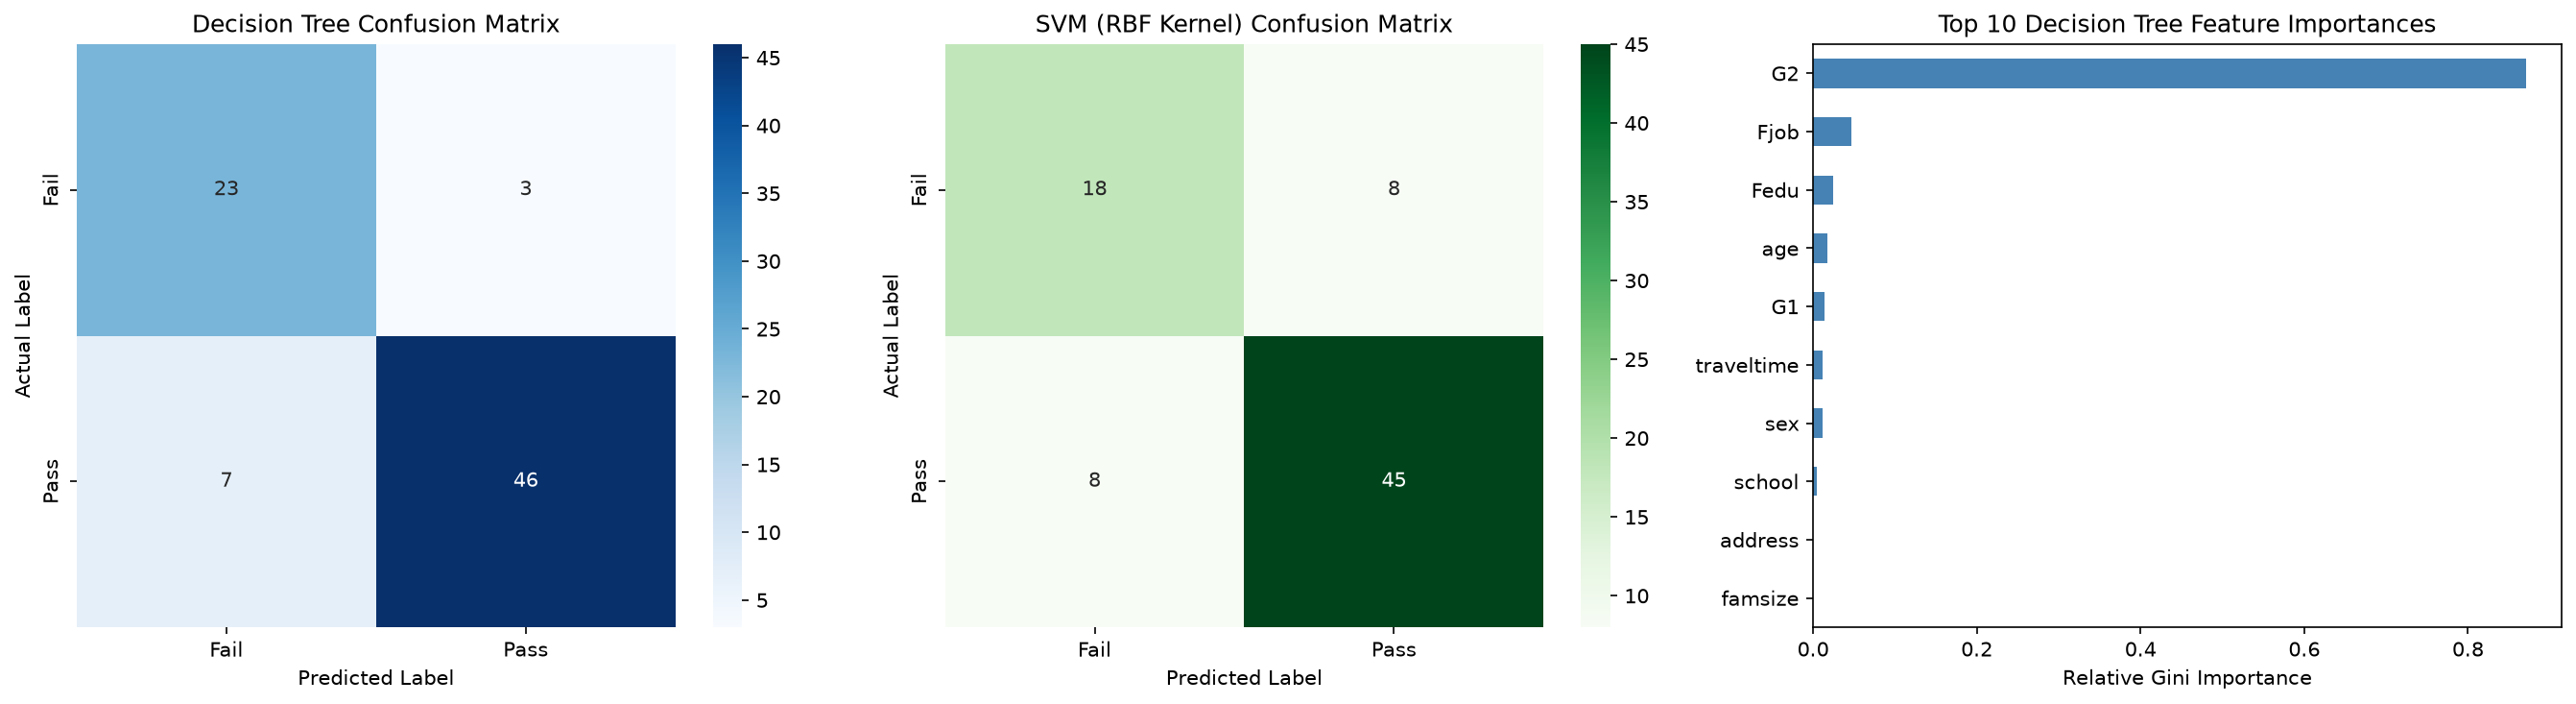

In [ ]:
fig, axes = plt.subplots(1, 3, figsize=(18, 5))

cm_dt = confusion_matrix(y_test, y_pred_dt)
sns.heatmap(
    cm_dt, annot=True, fmt="d", cmap="Blues", ax=axes[0],
    xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"]
)
axes[0].set_title("Decision Tree Confusion Matrix")
axes[0].set_xlabel("Predicted Label")
axes[0].set_ylabel("Actual Label")

cm_svm = confusion_matrix(y_test, y_pred_svm)
sns.heatmap(
    cm_svm, annot=True, fmt="d", cmap="Greens", ax=axes[1],
    xticklabels=["Fail", "Pass"], yticklabels=["Fail", "Pass"]
)
axes[1].set_title("SVM (RBF Kernel) Confusion Matrix")
axes[1].set_xlabel("Predicted Label")
axes[1].set_ylabel("Actual Label")

feat_importances = pd.Series(dt_model.feature_importances_, index=X_encoded.columns)
feat_importances.nlargest(10).plot(kind="barh", ax=axes[2], color="steelblue")
axes[2].set_title("Top 10 Decision Tree Feature Importances")
axes[2].set_xlabel("Relative Gini Importance")
axes[2].invert_yaxis()

plt.tight_layout()
plt.show()


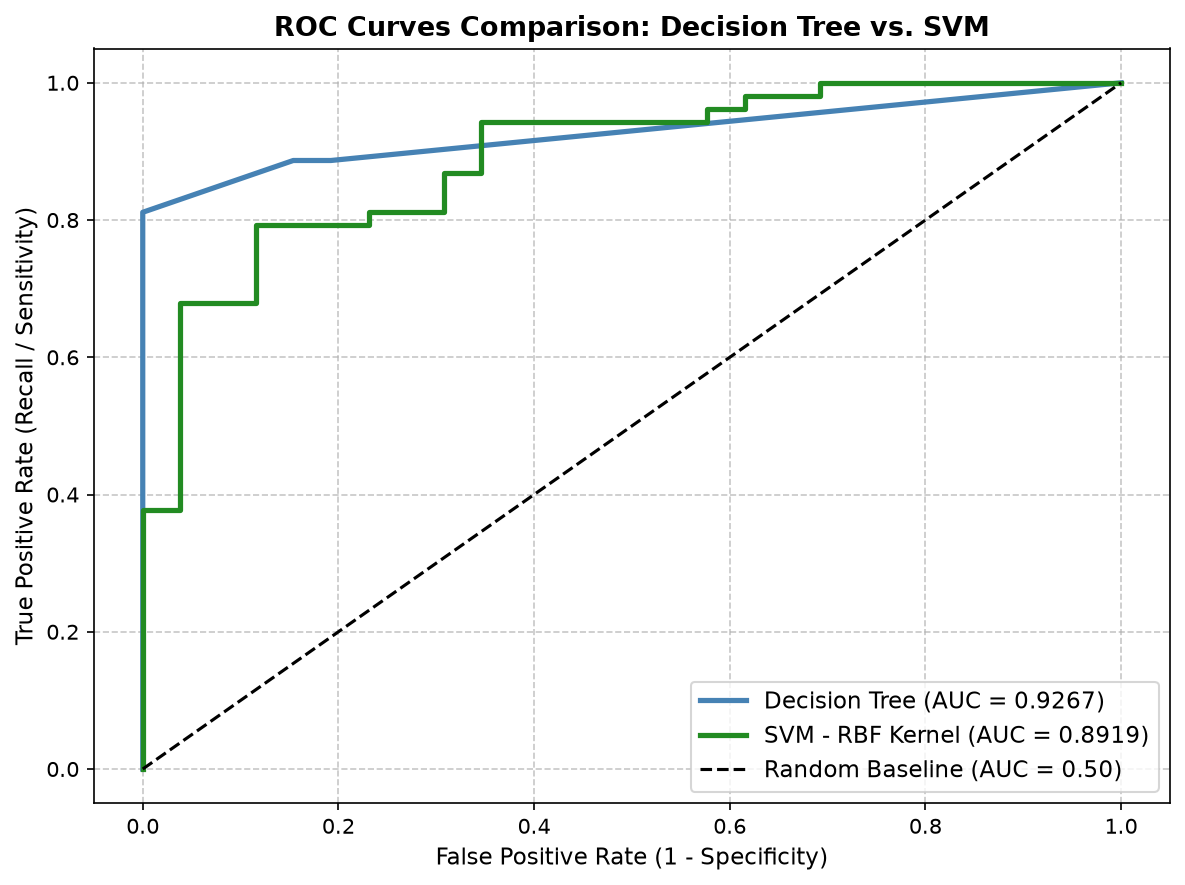

In [ ]:
fpr_dt, tpr_dt, _ = roc_curve(y_test, y_prob_dt)
fpr_svm, tpr_svm, _ = roc_curve(y_test, y_prob_svm)

plt.figure(figsize=(8, 6))
plt.plot(fpr_dt, tpr_dt, label=f"Decision Tree (AUC = {metrics_dt['ROC-AUC']:.4f})", color="steelblue", lw=2.5)
plt.plot(fpr_svm, tpr_svm, label=f"SVM - RBF Kernel (AUC = {metrics_svm['ROC-AUC']:.4f})", color="forestgreen", lw=2.5)
plt.plot([0, 1], [0, 1], "k--", lw=1.5, label="Random Baseline (AUC = 0.50)")

plt.title("ROC Curves Comparison: Decision Tree vs. SVM", fontsize=13, fontweight="bold")
plt.xlabel("False Positive Rate (1 - Specificity)", fontsize=11)
plt.ylabel("True Positive Rate (Recall / Sensitivity)", fontsize=11)
plt.legend(loc="lower right", fontsize=11)
plt.grid(True, linestyle="--", alpha=0.7)
plt.tight_layout()
plt.show()


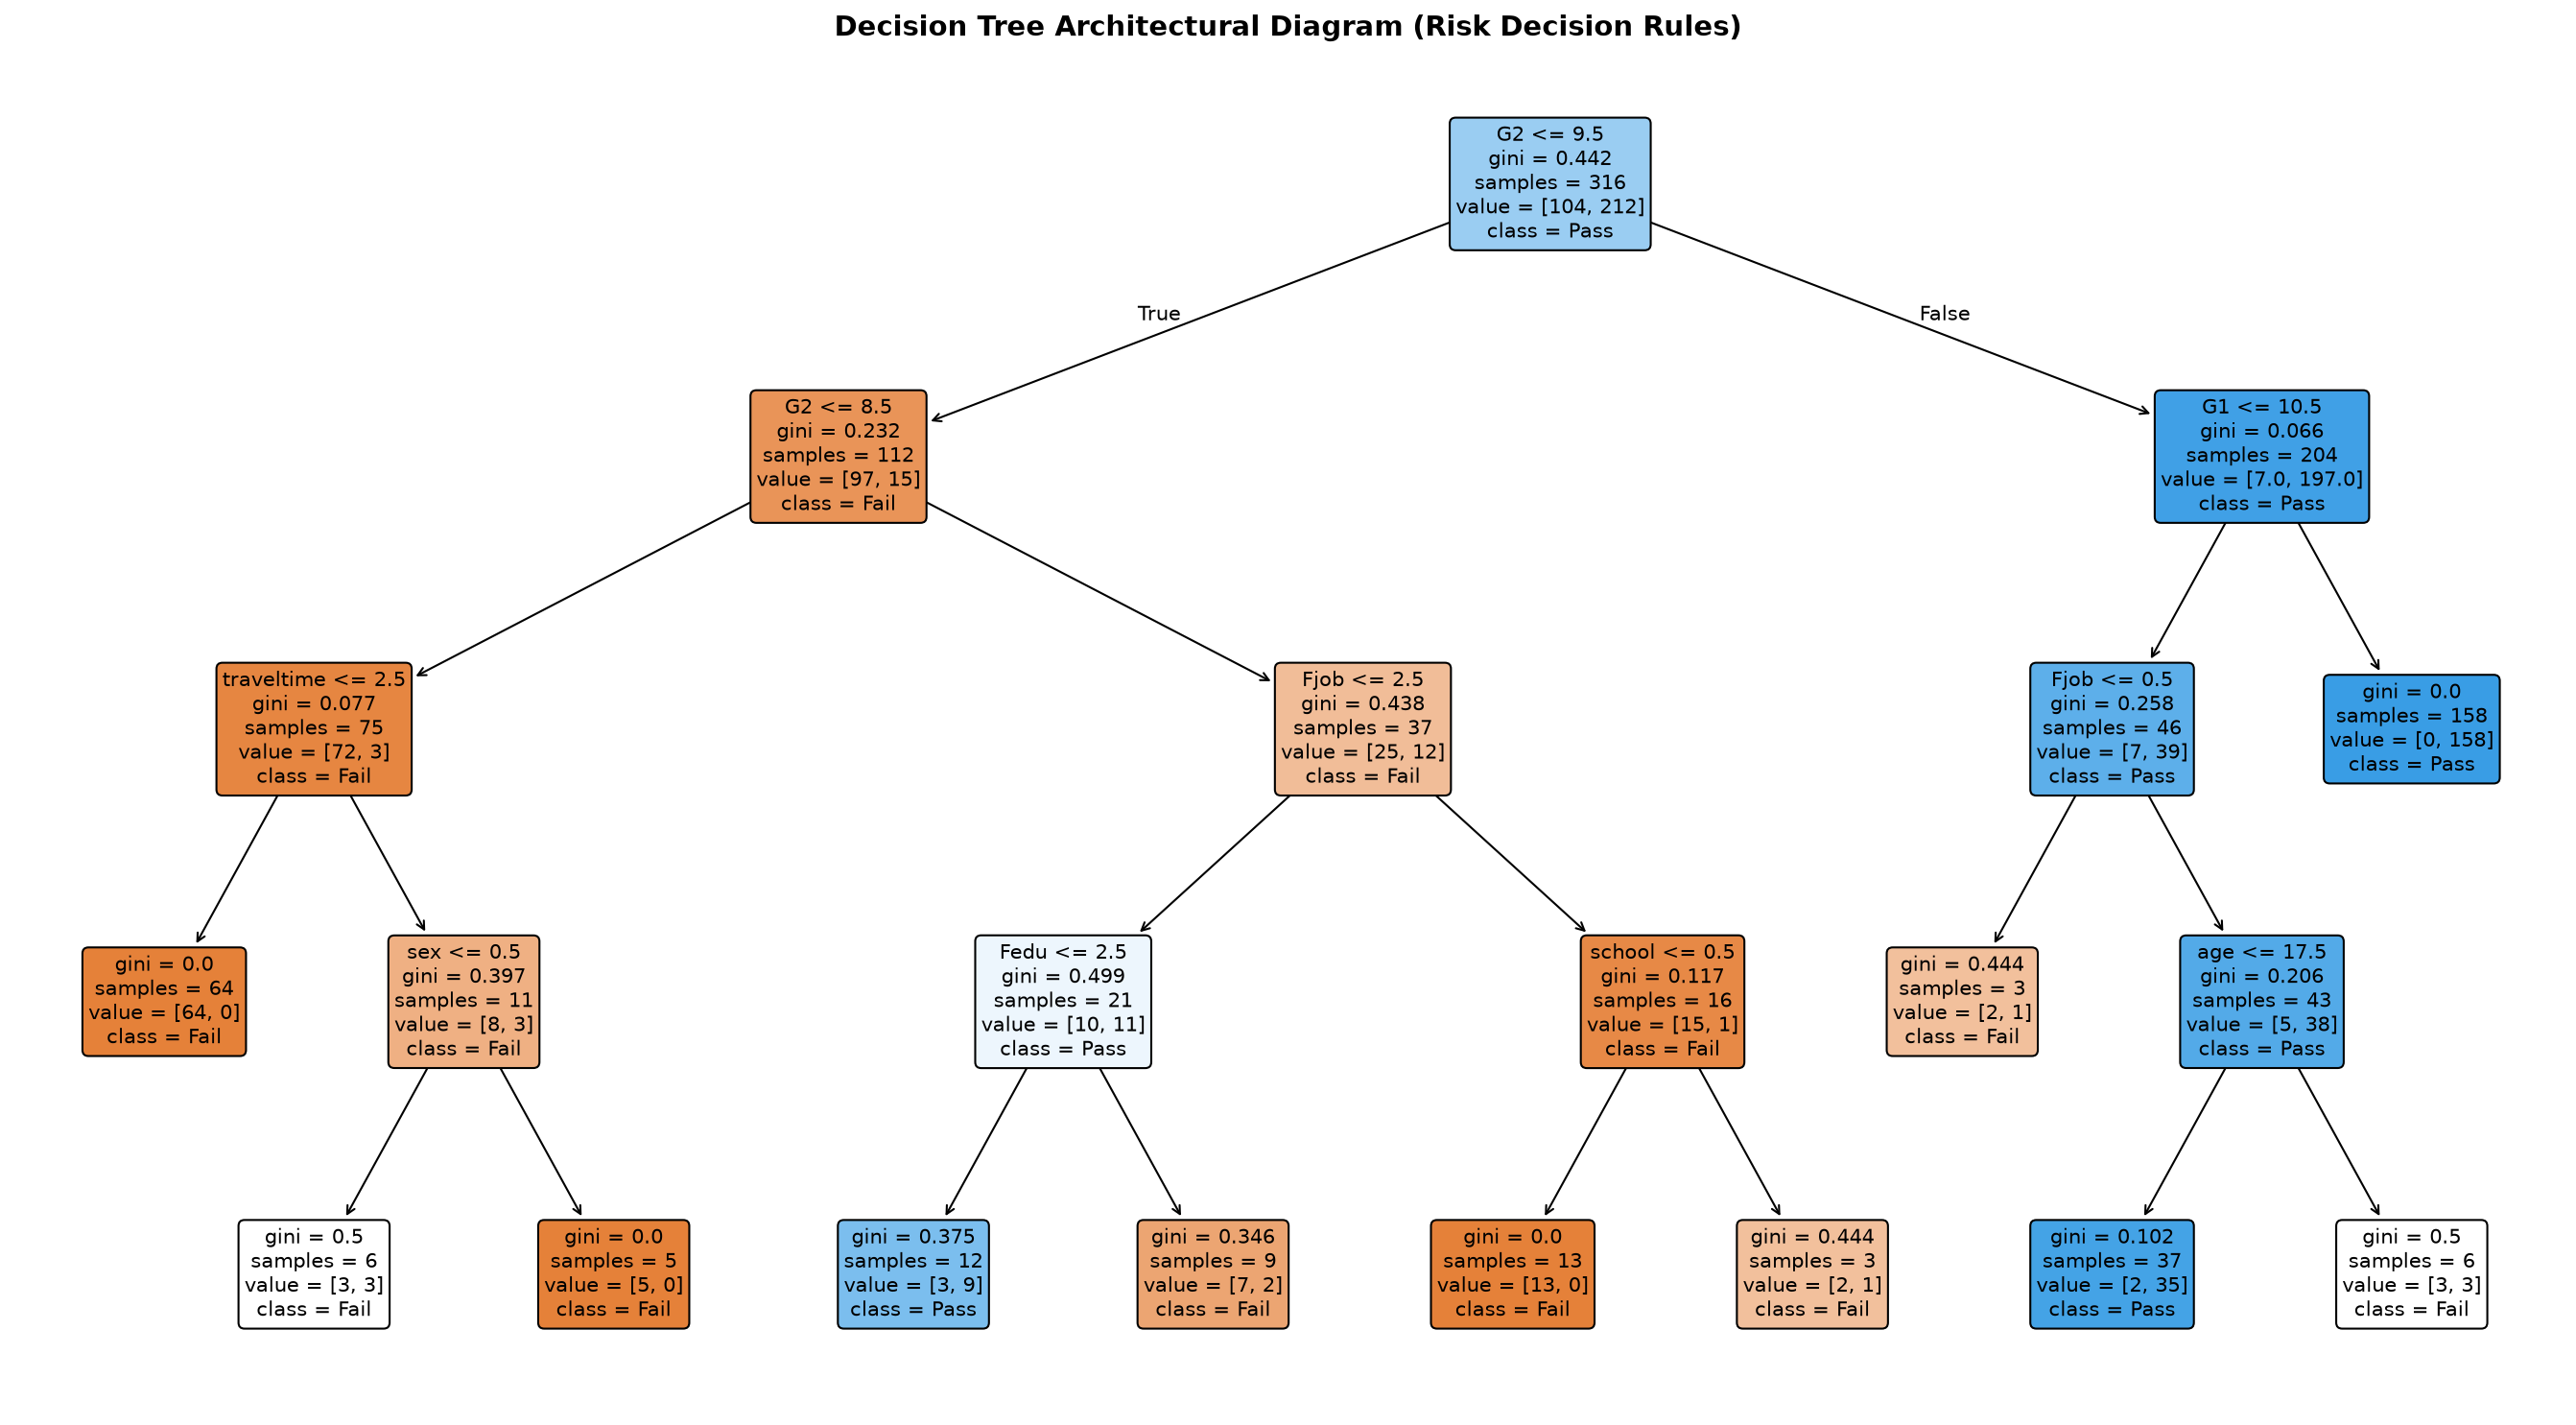

In [ ]:
plt.figure(figsize=(18, 10))
plot_tree(
    dt_model,
    feature_names=X_encoded.columns,
    class_names=["Fail", "Pass"],
    filled=True,
    rounded=True,
    fontsize=10
)
plt.title("Decision Tree Architectural Diagram (Risk Decision Rules)", fontsize=14, fontweight="bold")
plt.tight_layout()
plt.show()
